## Hydrodynamic model of the Southern North Sea

In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

# dataset helper
from helper import get_altimetry_obs, get_u_v_point_obs, get_wl_point_obs
from helper import plot_shred_reconstruction

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

from src.datamanager import DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSHRED import mSHRED

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


## Load Data and Measurement

In [3]:
# folders
dfs_fldr = "datasets/output/Area.dfsu"
msh_fldr = "datasets/input/Mesh_8000_elems_HD_v2.mesh"
obs_fldr  = "datasets/observations/"

msh = mikeio.open(msh_fldr)
dfs = mikeio.open(dfs_fldr)

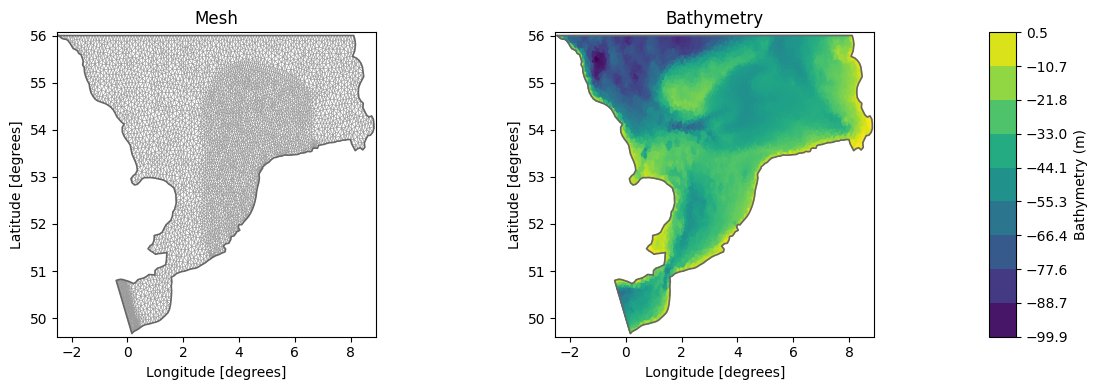

In [4]:
# plot geometry
geom = dfs.geometry

fig, axs = plt.subplots(1,2, figsize = (12,4))
geom.plot.mesh(ax=axs[0])
geom.plot(ax=axs[1])
plt.tight_layout()
plt.show()

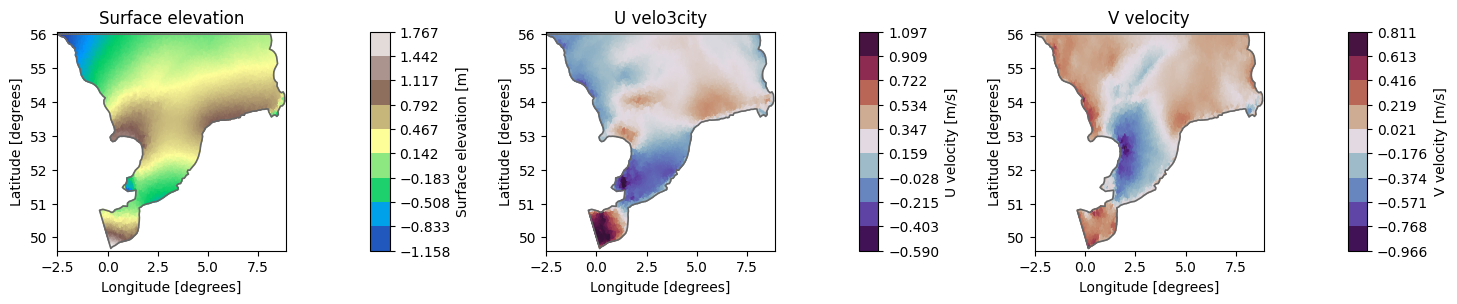

In [5]:
# plot a simulation
ds = dfs.read()

dsH = ds["Surface elevation"]
dsU = ds["U velocity"]
dsV = ds["V velocity"]

plot_time = ds.time[-1]
fig,axs = plt.subplots(1, 3, figsize=(15,5))
dsH.sel(time=plot_time).plot(ax=axs[0], title="Surface elevation", cmap = "terrain")
dsU.sel(time=plot_time).plot(ax=axs[1], title="U velo3city", cmap = "twilight_shifted")
dsV.sel(time=plot_time).plot(ax=axs[2], title="V velocity", cmap = "twilight_shifted")
plt.tight_layout()
plt.show()


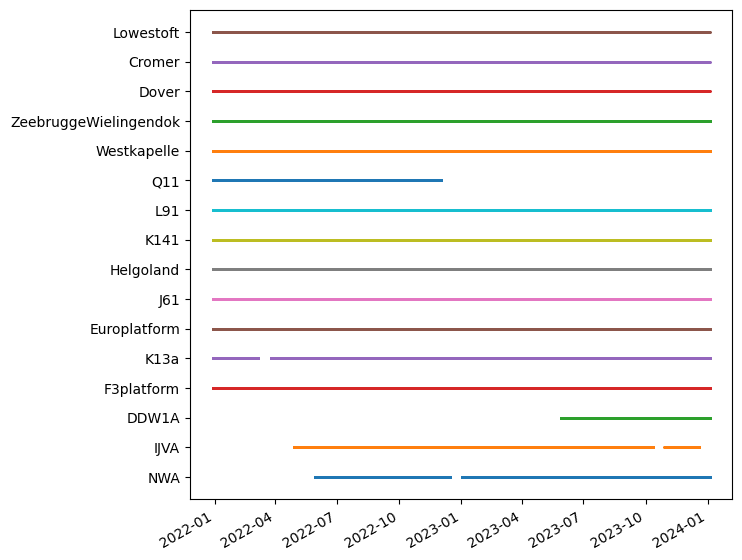

In [6]:
# sensor coverage

wllist = get_wl_point_obs()
ms.plotting.temporal_coverage(wllist);

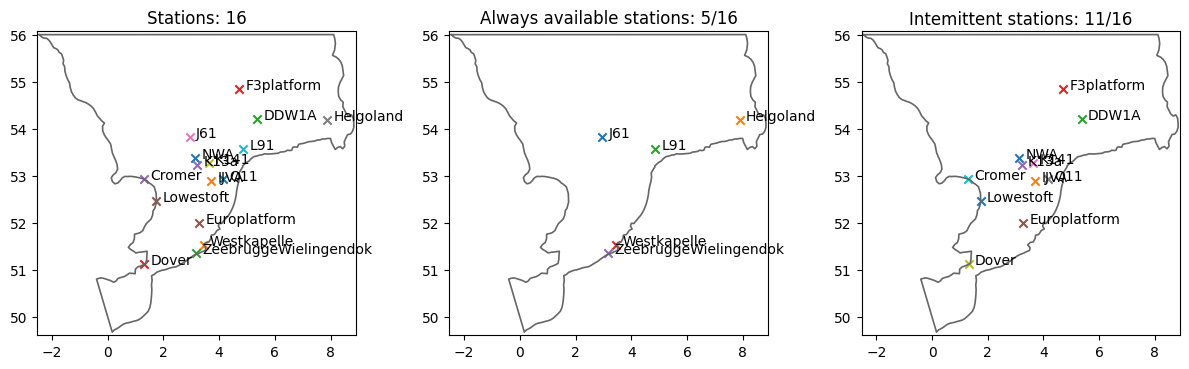

In [7]:
# Select stations with full temporal coverage

stations = []
availables = []
intermittent = []
for i in range(len(wllist)):
    stations.append(wllist[i])
    if ds.time.isin(wllist[i].time).all():
        availables.append(wllist[i])
    else:
        intermittent.append(wllist[i])

fig, axs = plt.subplots(1,3, figsize = (12,4))
ms.plotting.spatial_overview(stations, mod = msh.geometry, figsize = (5,5), ax=axs[0], title=f"Stations: {len(stations)}")
ms.plotting.spatial_overview(availables, mod = msh.geometry, figsize = (5,5), ax=axs[1], title=f"Always available stations: {len(availables)}/{len(stations)}")
ms.plotting.spatial_overview(intermittent, mod = msh.geometry, figsize = (5,5), ax=axs[2], title=f"Intemittent stations: {len(intermittent)}/{len(stations)}")

plt.tight_layout()
plt.show()


In [8]:
# Extract water level measurements

measurements = np.full((ds.time.shape[0], len(stations)), np.nan)

for i in range(len(stations)):
    
    stn_data = pd.read_csv(obs_fldr + stations[i].name + "_wl.csv", index_col = 0)
    measurements[:,i] = stn_data["water_level_filtered"].reindex(ds.time.strftime("%Y-%m-%d %H:%M:%S")).values 

# free memory
del stn_data

In [9]:
# Extract the values and convert to torch tensors

# remove nans from H, U, V 
dsH = dsH.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
dsU = dsU.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
dsV = dsV.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]

# outputs
H = torch.tensor(dsH, dtype=torch.float32)
U = torch.tensor(dsU, dtype=torch.float32)
V = torch.tensor(dsV, dtype=torch.float32)

# inputs
measurements = torch.tensor(measurements, dtype=torch.float32)

# print the shape of the arrays
print("H shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)
print("Measurements shape:", measurements.shape)

# free memory
del dsH, dsU, dsV

H shape: torch.Size([35039, 8532])
U shape: torch.Size([35039, 8532])
V shape: torch.Size([35039, 8532])
Measurements shape: torch.Size([35039, 16])


In [10]:
ERRORS = []

## Idea T.0: Only Available Sensors

In [11]:
# Extract measurements for always-available stations only
av_indices = [stations.index(s) for s in availables]
measurements_av = measurements[:, av_indices]

#counts nans
nan_counts_available = np.isnan(measurements_av.numpy()).sum(axis=0)
nan_counts_intermittent = np.isnan(measurements[:, [stations.index(s) for s in intermittent]].numpy()).sum(axis=0)

#available stations
print("Available stations:\n", [f"{s.name}: {nan_counts_available[i]}" for i, s in enumerate(availables)])
print("Intermittent stations:\n", [f"{s.name}: {nan_counts_intermittent[i]}" for i, s in enumerate(intermittent)])

# print the shape of the arrays
print("\nAfter selecting always-available stations only:")
print("H shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)
print("Measurements shape:", measurements_av.shape)

Available stations:
 ['J61: 0', 'Helgoland: 0', 'L91: 0', 'Westkapelle: 0', 'ZeebruggeWielingendok: 0']
Intermittent stations:
 ['NWA: 8570', 'IJVA: 8296', 'DDW1A: 25127', 'F3platform: 18', 'K13a: 1151', 'Europlatform: 435', 'K141: 67', 'Q11: 19139', 'Dover: 18015', 'Cromer: 18320', 'Lowestoft: 18051']

After selecting always-available stations only:
H shape: torch.Size([35039, 8532])
U shape: torch.Size([35039, 8532])
V shape: torch.Size([35039, 8532])
Measurements shape: torch.Size([35039, 5])


Nuber of nan values in measurements after imputation: 0 



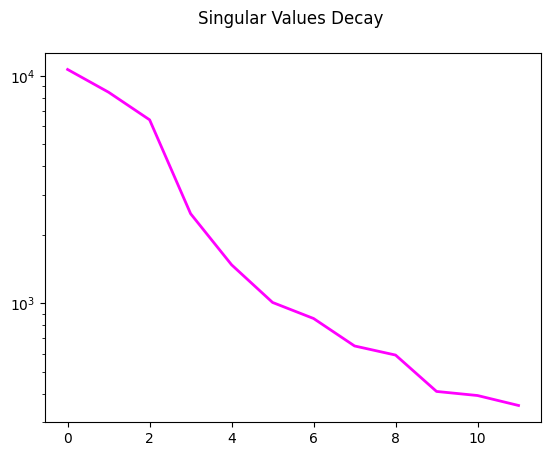

Residual energy of Surface elevation after keeping 12 modes: 0.1678 %


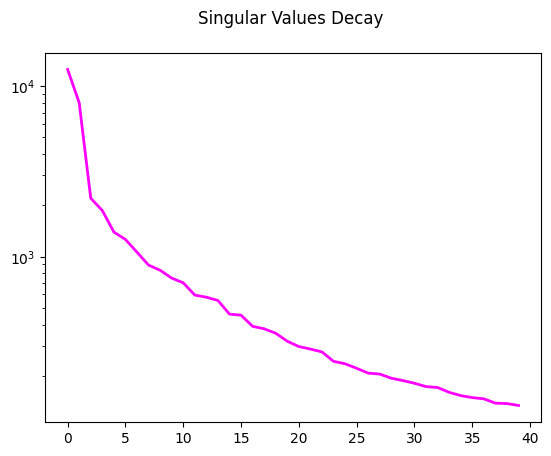

Residual energy of U velocity after keeping 40 modes: 0.1947 %


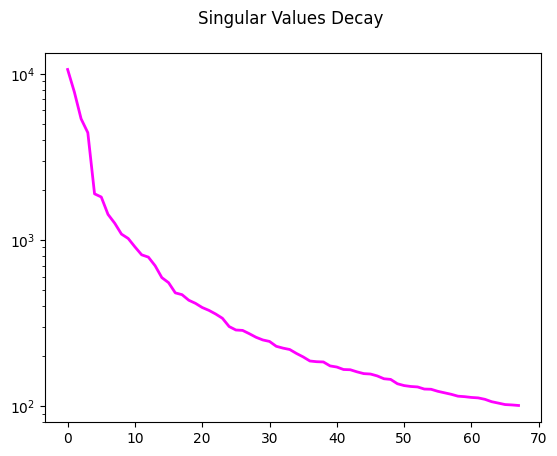

Residual energy of V velocity after keeping 68 modes: 0.1872 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([28031, 24, 5]) -> torch.Size([28031, 120])
Val:	 torch.Size([3504, 24, 5]) -> torch.Size([3504, 120])
Test:	 torch.Size([3504, 24, 5]) -> torch.Size([3504, 120])

Input shape for the model: 5
Output shape for the model: 120


In [12]:

# Data manager

lags = 24
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(H, id = "Surface elevation" , compress = 12, measurements = measurements_av, verbose = True)
manager.add_data(U, id = "U velocity", compress = 40, verbose = True)
manager.add_data(V, id = "V velocity", compress = 68, verbose = True)

# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True)

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = measurements_av.shape[1]
nn_output_shape = manager.data.shape[1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Starting training...


Training:  82%|████████▏ | 164/200 [18:50<04:08,  6.89s/it, Train Loss=0.0035, Val Loss=0.0040, Patience=59, Best Val Loss=0.0040, LR=7.37e-05]

Early stopping at epoch 165
Training completed with best validation loss: 0.0040


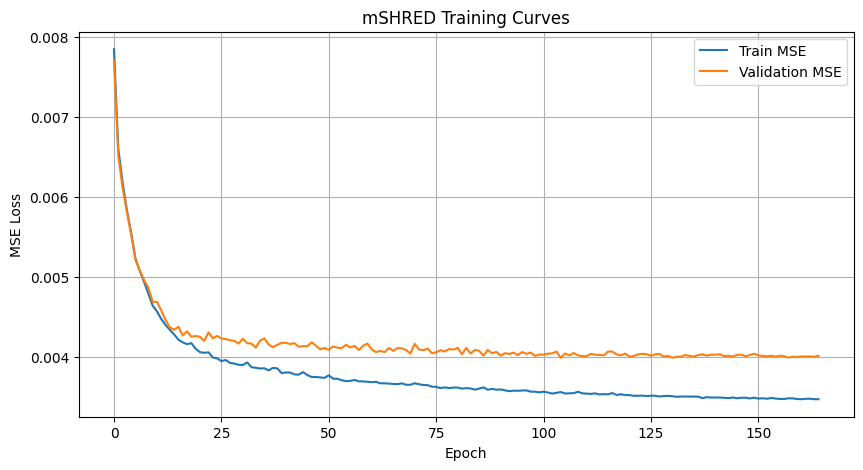

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.0) only available sensors,0.003557,0.003985,0.009561,0.120588,0.124742,0.194203


In [13]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=False
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + CNN",
    "type" : "(T.0) only available sensors",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_T_0_only_available_sensors.png


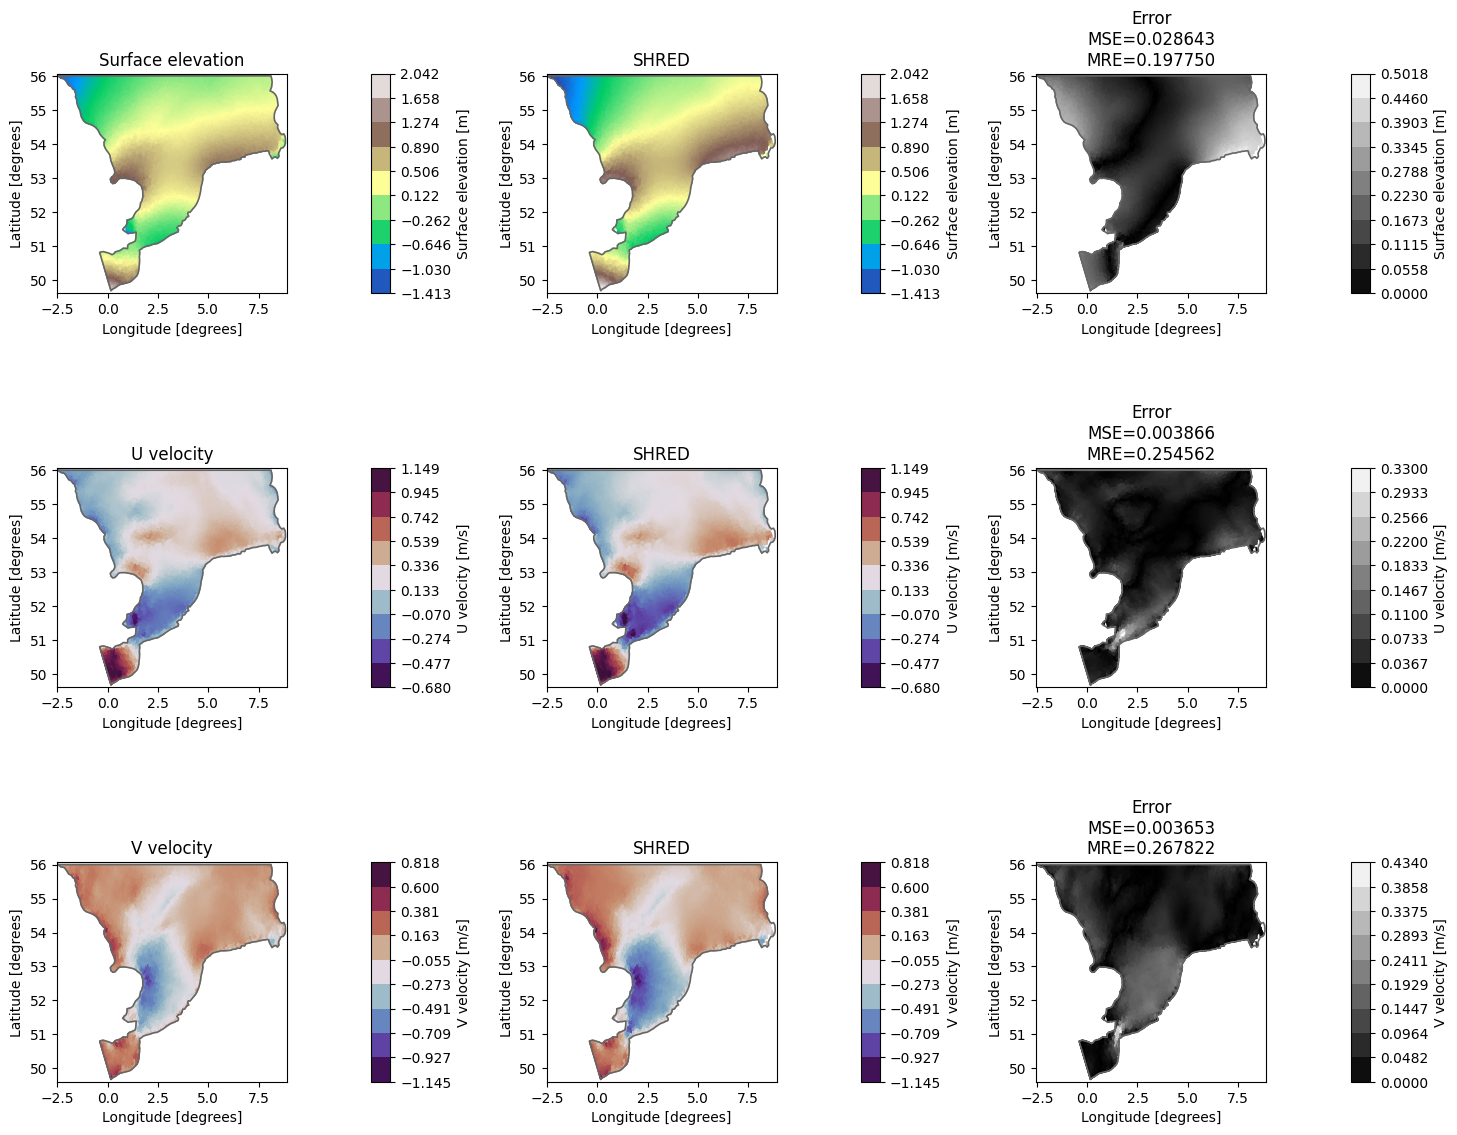

In [14]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="T_0_only_available_sensors")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea S.0: Only Available Sensors

Starting training...


Training:  78%|███████▊  | 155/200 [07:37<02:12,  2.95s/it, Train Loss=0.0033, Val Loss=0.0040, Patience=59, Best Val Loss=0.0040, LR=1.15e-04]

Early stopping at epoch 156
Training completed with best validation loss: 0.0040


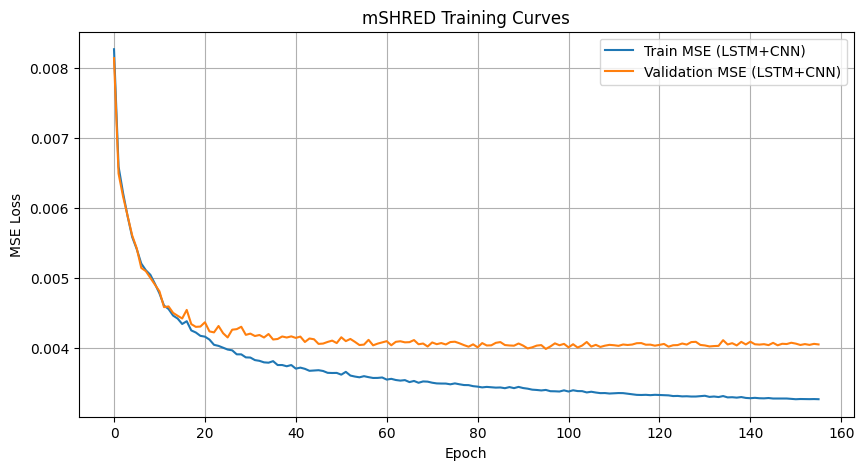

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.0) only available sensors,0.003557,0.003985,0.009561,0.120588,0.124742,0.194203
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.003394,0.003980,0.009891,0.118391,0.124265,0.196145


In [15]:

# mSHRED TRAINING (Idea S.0) - LSTM + CNN
model_args_s0 = dict(
    # Encoder
    encoder="lstm",
    input_size=nn_input_shape,
    hidden_size=32,
    num_layers=2,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args_s0).to(device)

train_errors_shred, valid_errors_shred = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors_shred, label='Train MSE (LSTM+CNN)')
plt.plot(valid_errors_shred, label='Validation MSE (LSTM+CNN)')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse_shred, train_mre_shred = evaluate(mshred, train_dataset)
val_mse_shred, val_mre_shred = evaluate(mshred, val_dataset)
test_mse_shred, test_mre_shred = evaluate(mshred, test_dataset)
test_error = {
    "model": "(mSHRED) LSTM + CNN",
    "type": "(S.0) only available sensors",
    "train-mse": float(train_mse_shred),
    "val-mse": float(val_mse_shred),
    "test-mse": float(test_mse_shred),
    "train-mre": float(train_mre_shred),
    "val-mre": float(val_mre_shred),
    "test-mre": float(test_mre_shred),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_S_0_only_available_sensors.png


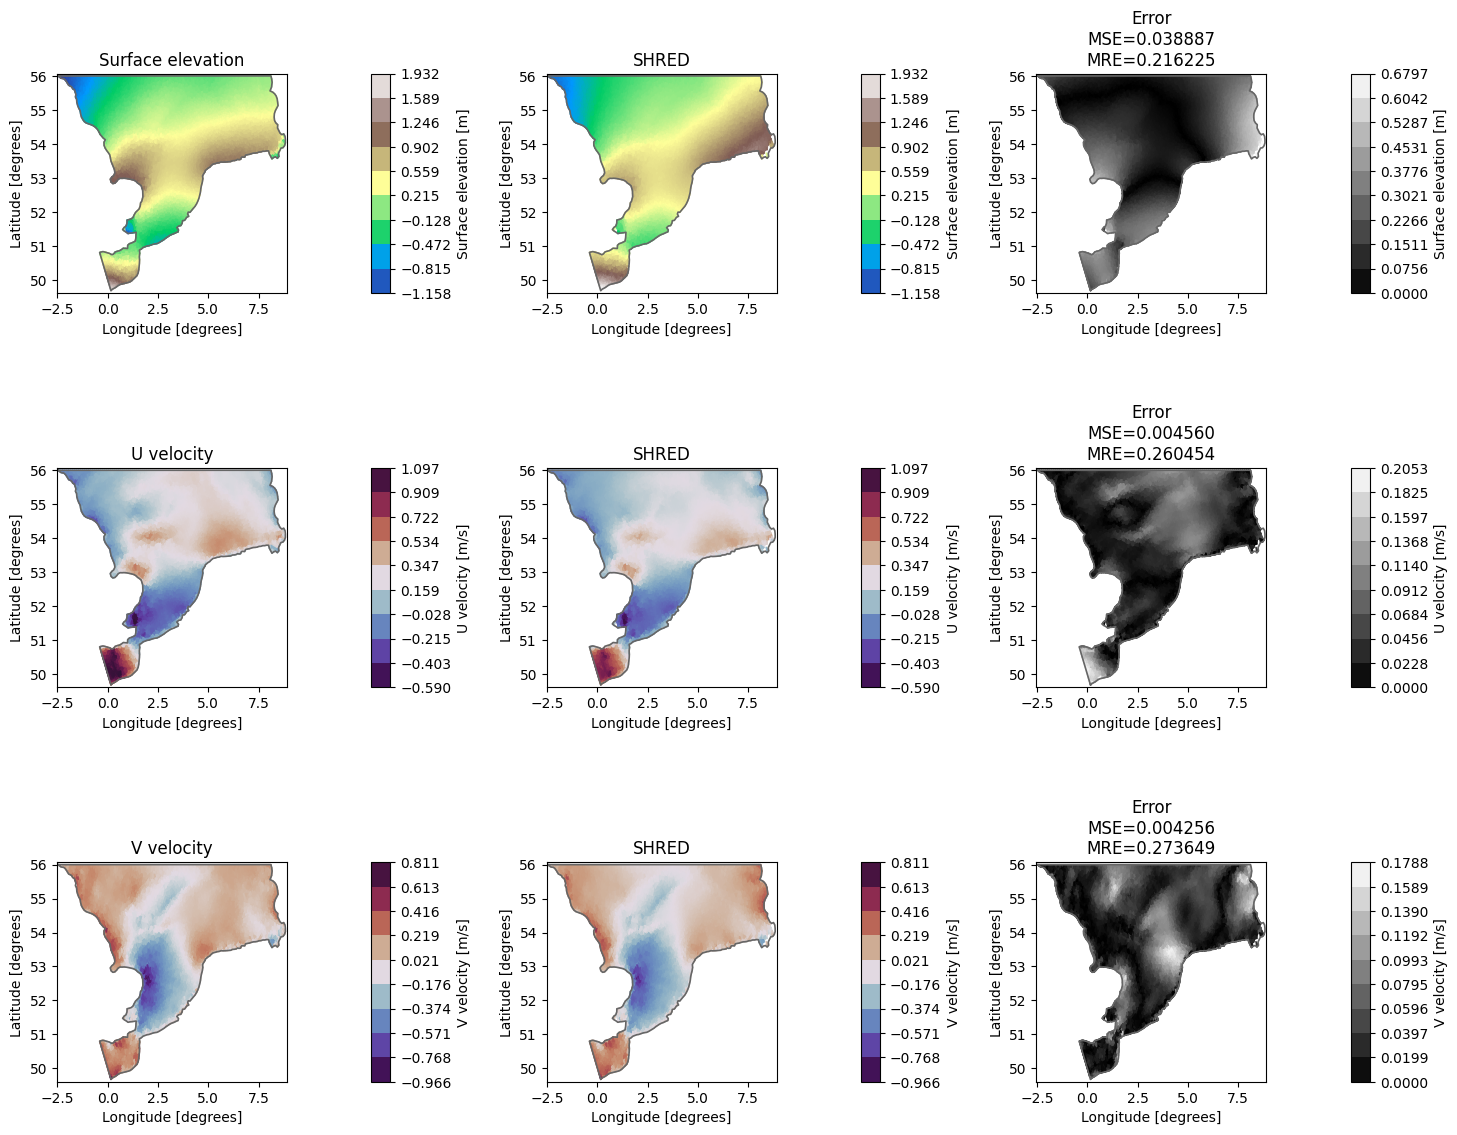

In [16]:

# SHRED RECONSTRUCTION (Idea S.0)
engine_shred = SHREDEngine(manager, mshred)
test_reconstruction_shred = engine_shred.sensor_to_reconstruction_dataset(test_dataset)
ds_shred_s0, ds_error_s0 = plot_shred_reconstruction(test_reconstruction_shred, ds, geom, title_suffix="S_0_only_available_sensors")

del engine_shred, test_reconstruction_shred, ds_shred_s0, ds_error_s0, mshred, manager


## Idea T.1.A: Median imputer

In [17]:

# Data manager

lags = 24
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(
    H, id = "Surface elevation" , compress = 12, 
    measurements = measurements, imputer="median"
)
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True)

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = measurements.shape[1]
nn_output_shape = manager.data.shape[1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Nuber of nan values in measurements after imputation: 0 

Residual energy of Surface elevation after keeping 12 modes: 0.1678 %
Residual energy of U velocity after keeping 40 modes: 0.1947 %
Residual energy of V velocity after keeping 68 modes: 0.1872 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([28031, 24, 16]) -> torch.Size([28031, 120])
Val:	 torch.Size([3504, 24, 16]) -> torch.Size([3504, 120])
Test:	 torch.Size([3504, 24, 16]) -> torch.Size([3504, 120])

Input shape for the model: 16
Output shape for the model: 120


Starting training...


Training: 100%|██████████| 200/200 [31:11<00:00,  9.36s/it, Train Loss=0.0038, Val Loss=0.0041, Patience=2, Best Val Loss=0.0040, LR=0.00e+00] 

Training completed with best validation loss: 0.0040


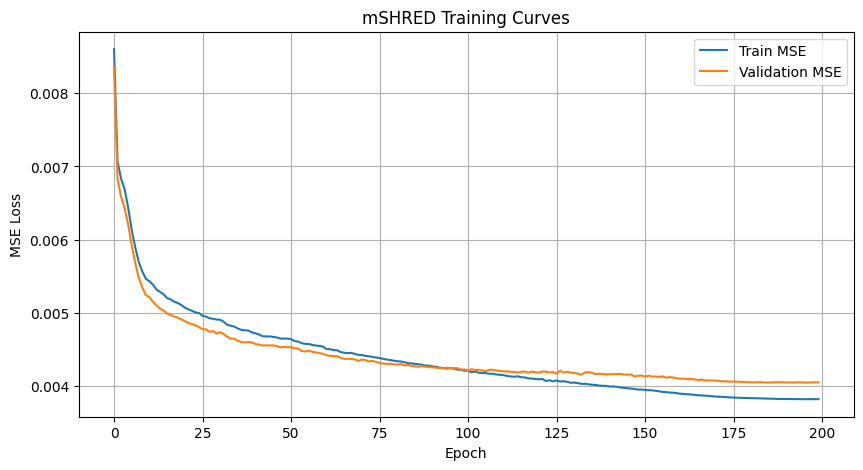

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.0) only available sensors,0.003866,0.004088,0.009840,0.124958,0.126123,0.196637
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.003766,0.004077,0.009829,0.123386,0.125691,0.195788
2,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.003823,0.004051,0.009776,0.124557,0.125758,0.195697


In [18]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + CNN",
    "type" : "(T.1.A) median imputation for missing sensors",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_T_1_A_median_imputation.png


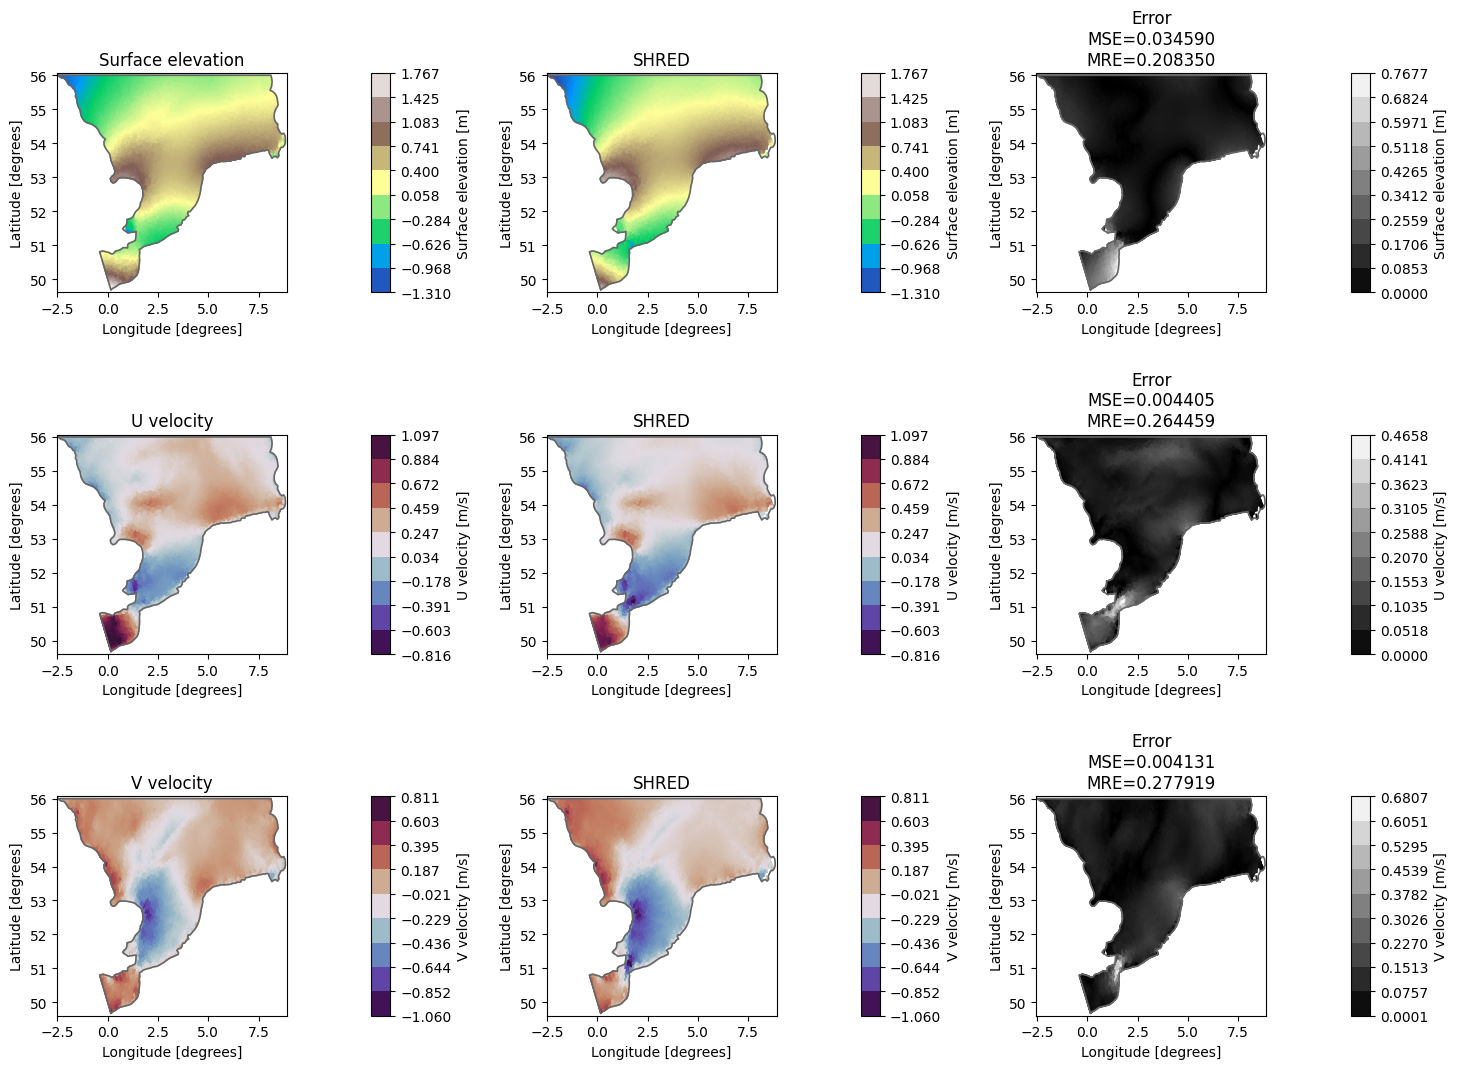

In [ ]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction(manager.test_sensor_measurements)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="T_1_A_median_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea S.1.A: Median imputer 


Starting training...


Training: 100%|██████████| 200/200 [09:38<00:00,  2.89s/it, Train Loss=0.0037, Val Loss=0.0040, Patience=6, Best Val Loss=0.0040, LR=0.00e+00] 

Training completed with best validation loss: 0.0040


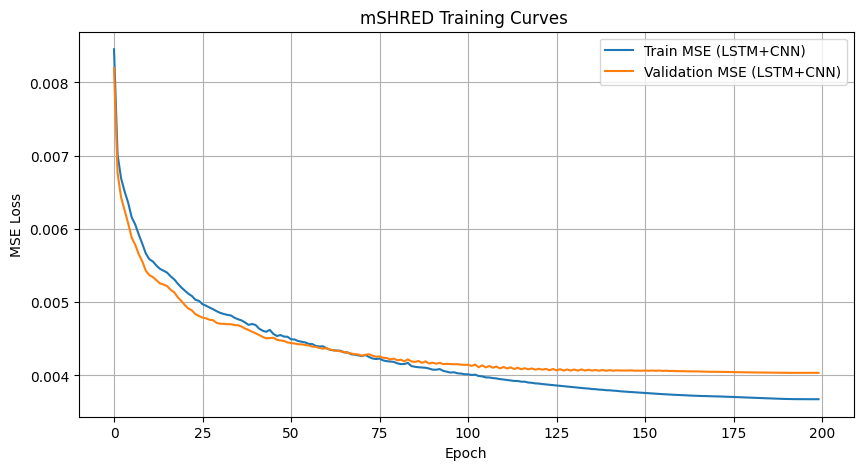

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.0) only available sensors,0.003866,0.004088,0.009840,0.124958,0.126123,0.196637
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.003766,0.004077,0.009829,0.123386,0.125691,0.195788
2,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.003823,0.004051,0.009776,0.124557,0.125758,0.195697
3,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.003676,0.004036,0.010085,0.122717,0.125418,0.197708


In [ ]:

# mSHRED TRAINING (Idea S.1.A) - LSTM + CNN
model_args_s0 = dict(
    # Encoder
    encoder="lstm",
    input_size=nn_input_shape,
    hidden_size=32,
    num_layers=2,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args_s0).to(device)

train_errors_shred, valid_errors_shred = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors_shred, label='Train MSE (LSTM+CNN)')
plt.plot(valid_errors_shred, label='Validation MSE (LSTM+CNN)')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves ')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse_shred, train_mre_shred = evaluate(mshred, train_dataset)
val_mse_shred, val_mre_shred = evaluate(mshred, val_dataset)
test_mse_shred, test_mre_shred = evaluate(mshred, test_dataset)
test_error = {
    "model": "(mSHRED) LSTM + CNN",
    "type": "(S.1.A) median imputation for missing sensors",
    "train-mse": float(train_mse_shred),
    "val-mse": float(val_mse_shred),
    "test-mse": float(test_mse_shred),
    "train-mre": float(train_mre_shred),
    "val-mre": float(val_mre_shred),
    "test-mre": float(test_mre_shred),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_S_1_A_median_imputation.png


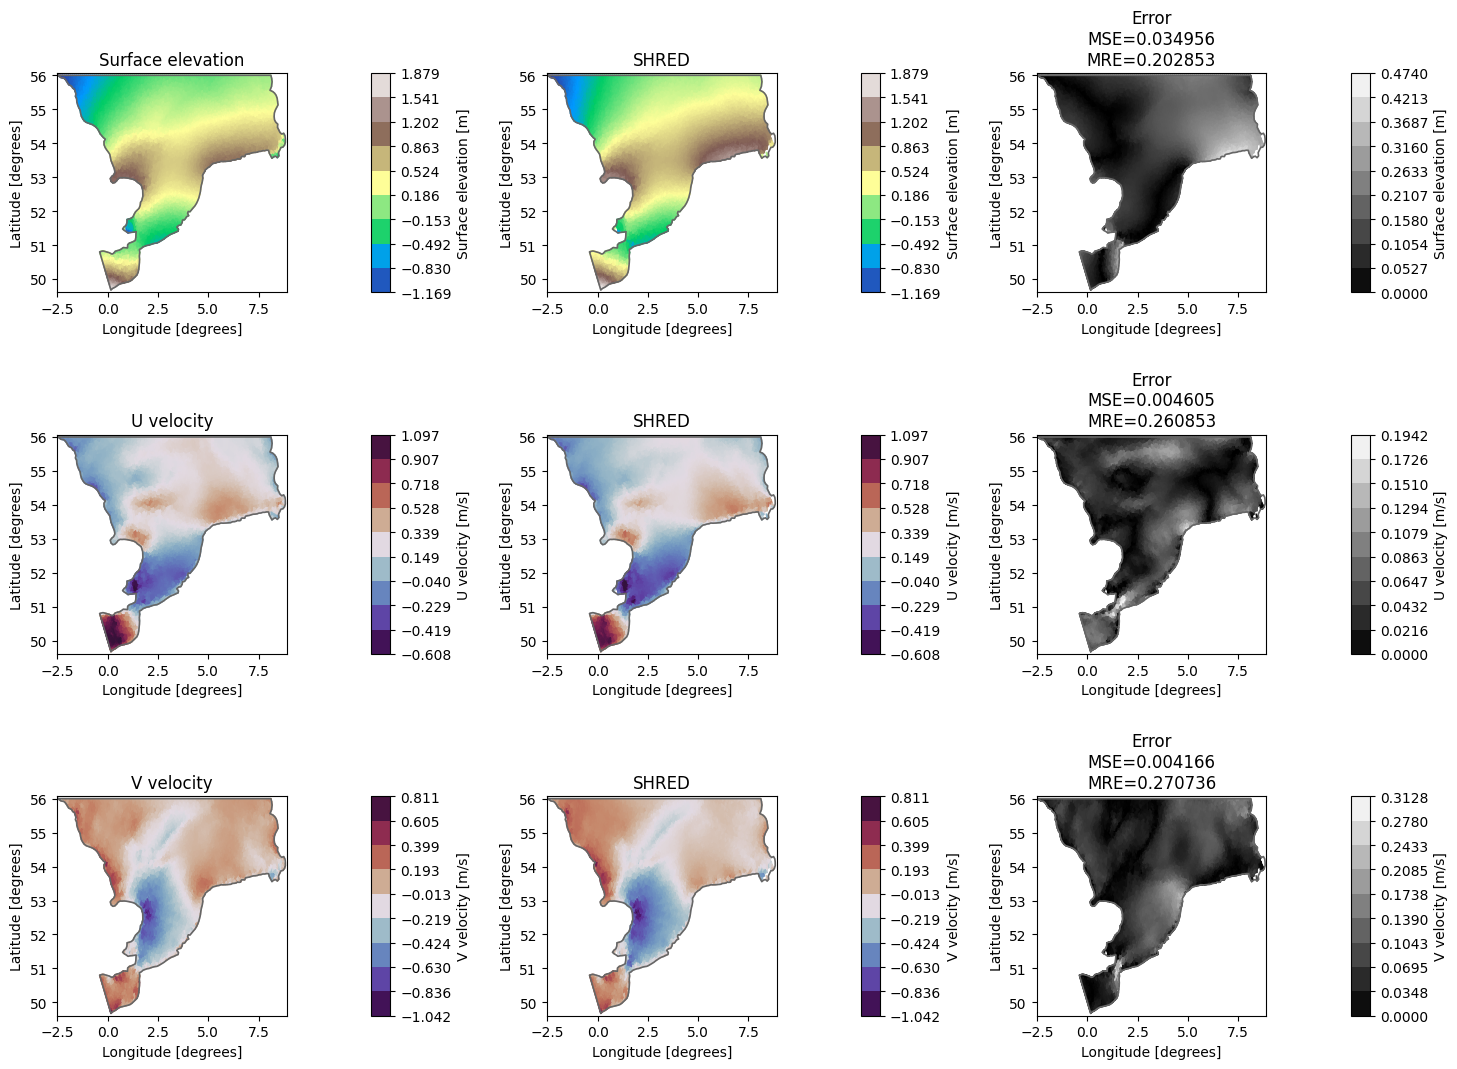

In [ ]:

# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction(manager.test_sensor_measurements)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="S_1_A_median_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager


## Idea T.1.B: Mean imputer

In [ ]:
# Data manager

lags = 24
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(
    H, id = "Surface elevation" , compress = 12, 
    measurements = measurements, imputer="mean"
)
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True)

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = measurements.shape[1]
nn_output_shape = manager.data.shape[1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Nuber of nan values in measurements after imputation: 0 

Residual energy of Surface elevation after keeping 12 modes: 0.1678 %
Residual energy of U velocity after keeping 40 modes: 0.1947 %
Residual energy of V velocity after keeping 68 modes: 0.1872 %

 Data shapes after preparation:
Train:	 torch.Size([28031, 24, 16]) -> torch.Size([28031, 120])
Val:	 torch.Size([3504, 24, 16]) -> torch.Size([3504, 120])
Test:	 torch.Size([3504, 24, 16]) -> torch.Size([3504, 120])

Input shape for the model: 16
Output shape for the model: 120


Starting training...


Training: 100%|██████████| 200/200 [28:08<00:00,  8.44s/it, Train Loss=0.0038, Val Loss=0.0040, Patience=2, Best Val Loss=0.0040, LR=0.00e+00]

Training completed with best validation loss: 0.0040


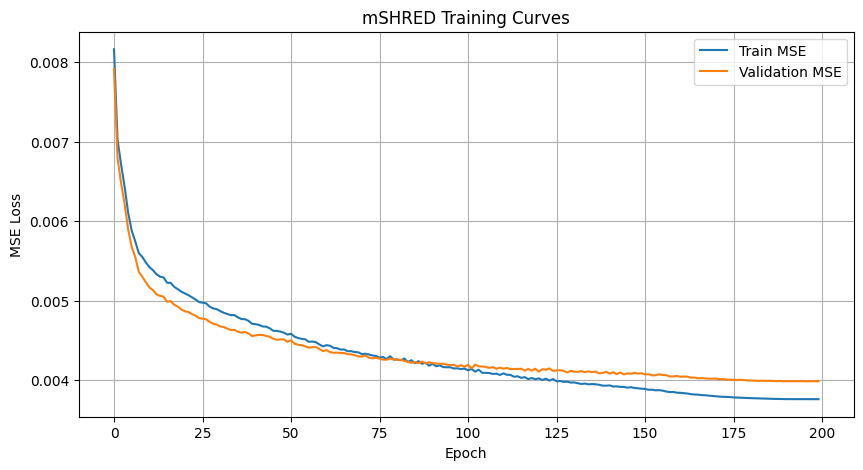

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.0) only available sensors,0.003866,0.004088,0.009840,0.124958,0.126123,0.196637
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.003766,0.004077,0.009829,0.123386,0.125691,0.195788
2,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.003823,0.004051,0.009776,0.124557,0.125758,0.195697
3,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.003676,0.004036,0.010085,0.122717,0.125418,0.197708
4,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.003764,0.003990,0.009698,0.123587,0.124648,0.194954


In [ ]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + CNN",
    "type" : "(T.1.B) mean imputation for missing sensors",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_T_1_B_mean_imputation.png


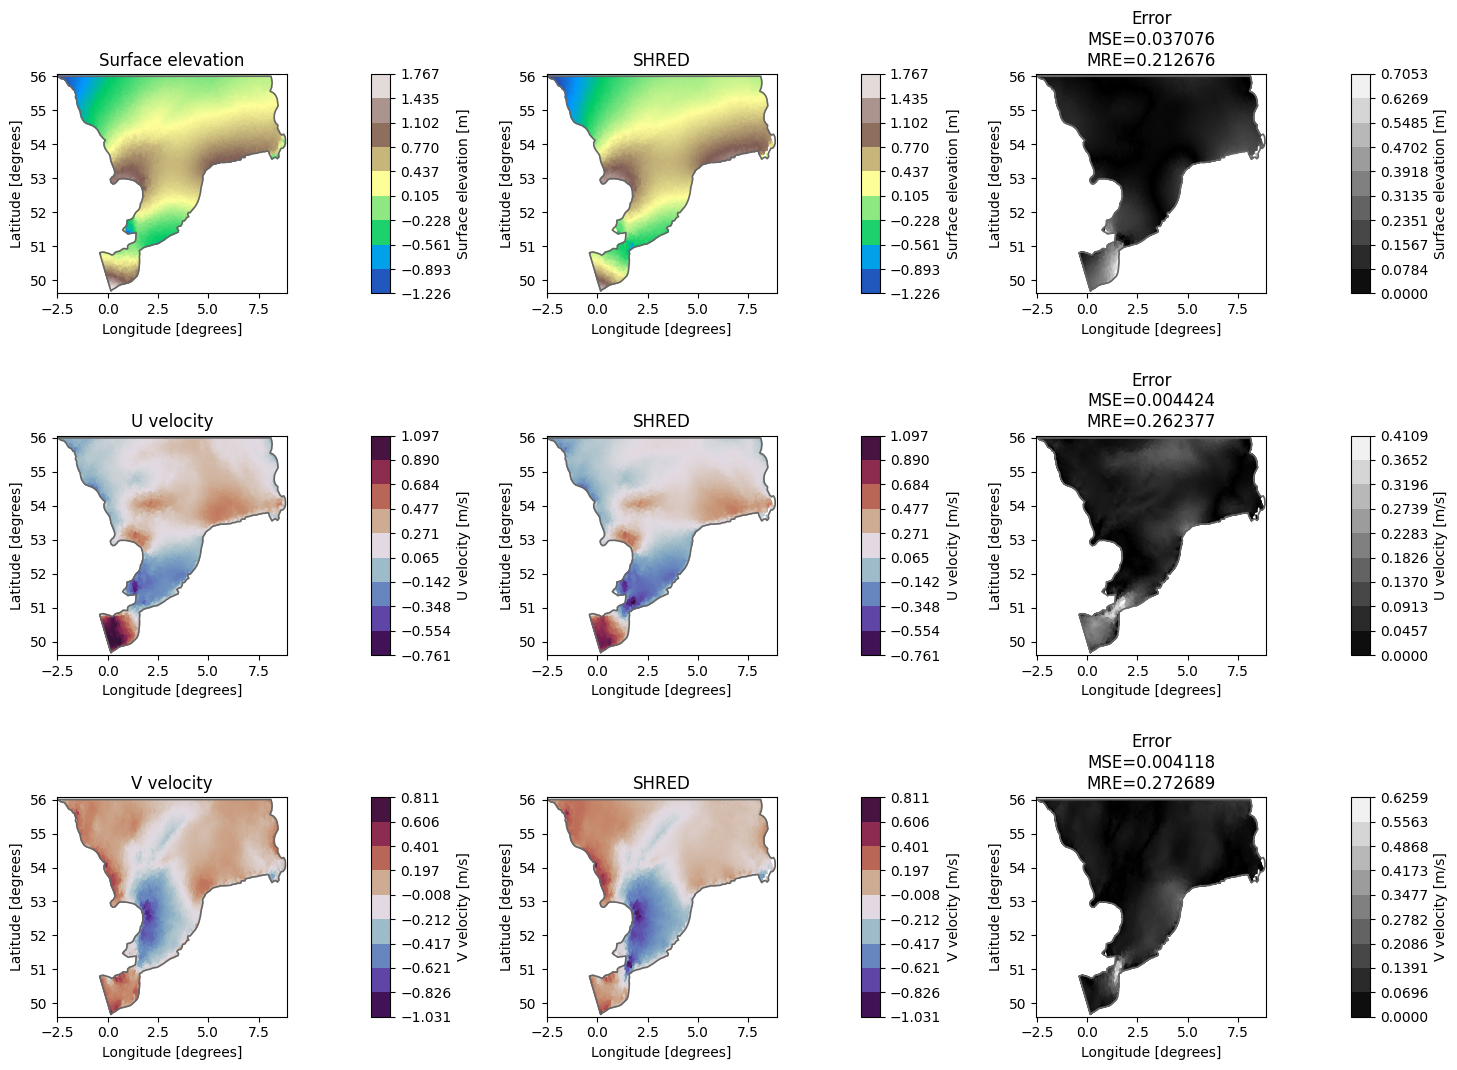

In [ ]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction(manager.test_sensor_measurements)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="T_1_B_mean_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea S.1.B: Mean imputer

Starting training...


Training: 100%|██████████| 200/200 [09:54<00:00,  2.97s/it, Train Loss=0.0036, Val Loss=0.0040, Patience=6, Best Val Loss=0.0040, LR=0.00e+00] 

Training completed with best validation loss: 0.0040


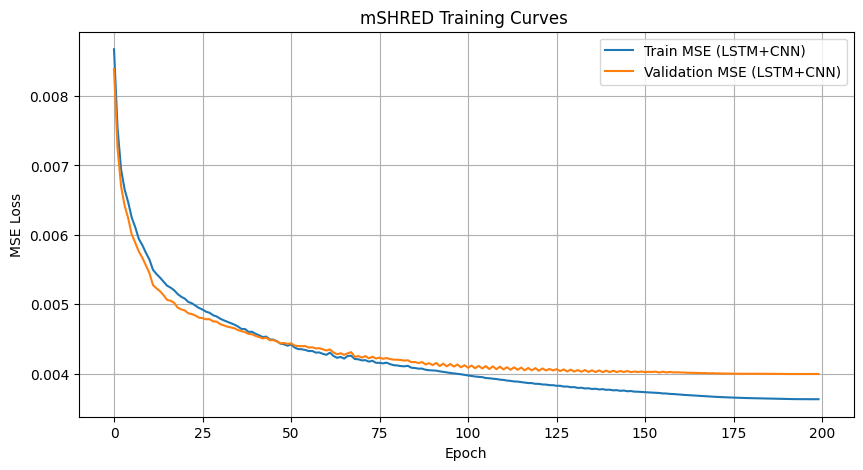

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.0) only available sensors,0.003866,0.004088,0.009840,0.124958,0.126123,0.196637
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.003766,0.004077,0.009829,0.123386,0.125691,0.195788
2,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.003823,0.004051,0.009776,0.124557,0.125758,0.195697
3,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.003676,0.004036,0.010085,0.122717,0.125418,0.197708
4,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.003764,0.003990,0.009698,0.123587,0.124648,0.194954
5,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.003631,0.003994,0.009914,0.121811,0.124570,0.196031


In [ ]:

# mSHRED TRAINING (Idea S.1.B) - LSTM + CNN
model_args_s0 = dict(
    # Encoder
    encoder="lstm",
    input_size=nn_input_shape,
    hidden_size=32,
    num_layers=2,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args_s0).to(device)

train_errors_shred, valid_errors_shred = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors_shred, label='Train MSE (LSTM+CNN)')
plt.plot(valid_errors_shred, label='Validation MSE (LSTM+CNN)')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves ')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse_shred, train_mre_shred = evaluate(mshred, train_dataset)
val_mse_shred, val_mre_shred = evaluate(mshred, val_dataset)
test_mse_shred, test_mre_shred = evaluate(mshred, test_dataset)
test_error = {
    "model": "(mSHRED) LSTM + CNN",
    "type": "(S.1.B) mean imputation for missing sensors",
    "train-mse": float(train_mse_shred),
    "val-mse": float(val_mse_shred),
    "test-mse": float(test_mse_shred),
    "train-mre": float(train_mre_shred),
    "val-mre": float(val_mre_shred),
    "test-mre": float(test_mre_shred),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_S_1_B_mean_imputation.png


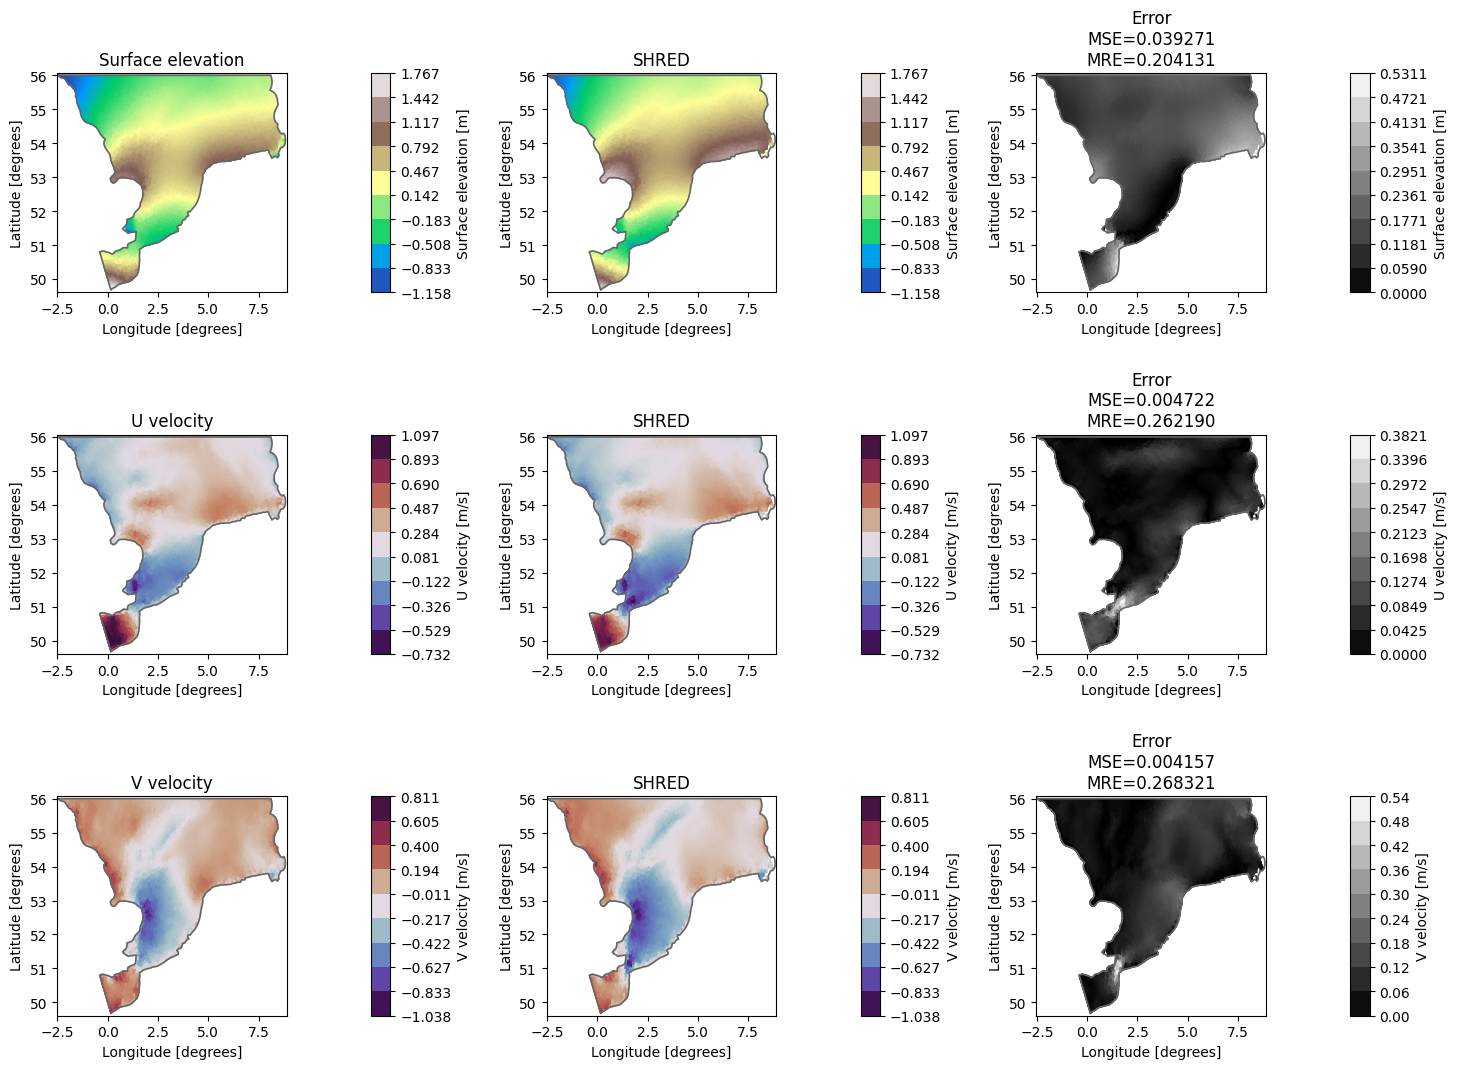

In [ ]:

# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction(manager.test_sensor_measurements)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="S_1_B_mean_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager


## Idea T.1.C: Last value imputer

In [ ]:

# Data manager

lags = 24
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(
    H, id = "Surface elevation" , compress = 12, 
    measurements = measurements, imputer="last_value"
 )
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True)

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = measurements.shape[1]
nn_output_shape = manager.data.shape[1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Nuber of nan values in measurements after imputation: 0 

Residual energy of Surface elevation after keeping 12 modes: 0.1678 %
Residual energy of U velocity after keeping 40 modes: 0.1947 %
Residual energy of V velocity after keeping 68 modes: 0.1872 %

 Data shapes after preparation:
Train:	 torch.Size([28031, 24, 16]) -> torch.Size([28031, 120])
Val:	 torch.Size([3504, 24, 16]) -> torch.Size([3504, 120])
Test:	 torch.Size([3504, 24, 16]) -> torch.Size([3504, 120])

Input shape for the model: 16
Output shape for the model: 120


Starting training...


Training: 100%|██████████| 200/200 [24:38<00:00,  7.39s/it, Train Loss=0.0037, Val Loss=0.0040, Patience=1, Best Val Loss=0.0040, LR=0.00e+00] 

Training completed with best validation loss: 0.0040


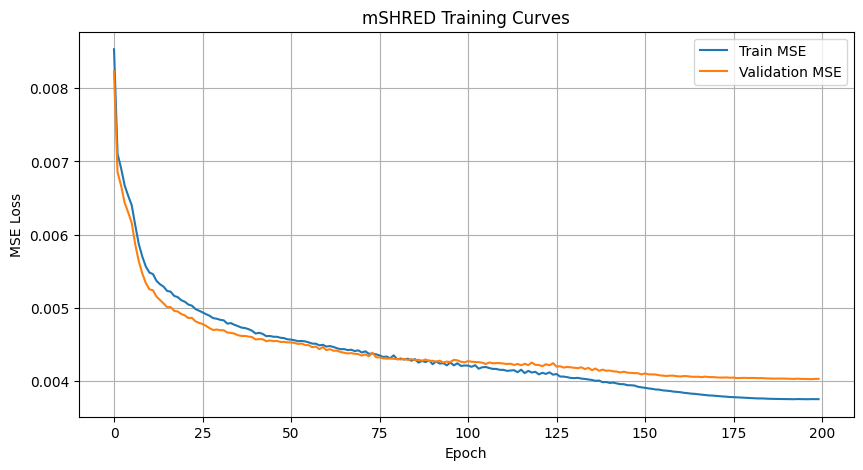

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.0) only available sensors,0.003866,0.004088,0.009840,0.124958,0.126123,0.196637
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.003766,0.004077,0.009829,0.123386,0.125691,0.195788
2,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.003823,0.004051,0.009776,0.124557,0.125758,0.195697
3,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.003676,0.004036,0.010085,0.122717,0.125418,0.197708
4,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.003764,0.003990,0.009698,0.123587,0.124648,0.194954
5,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.003631,0.003994,0.009914,0.121811,0.124570,0.196031
6,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.003748,0.004025,0.009657,0.123510,0.125180,0.194356


In [ ]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=32,
    input_length=lags,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + CNN",
    "type" : "(T.1.C) last value imputation for missing sensors",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_T_1_C_last_value_imputation.png


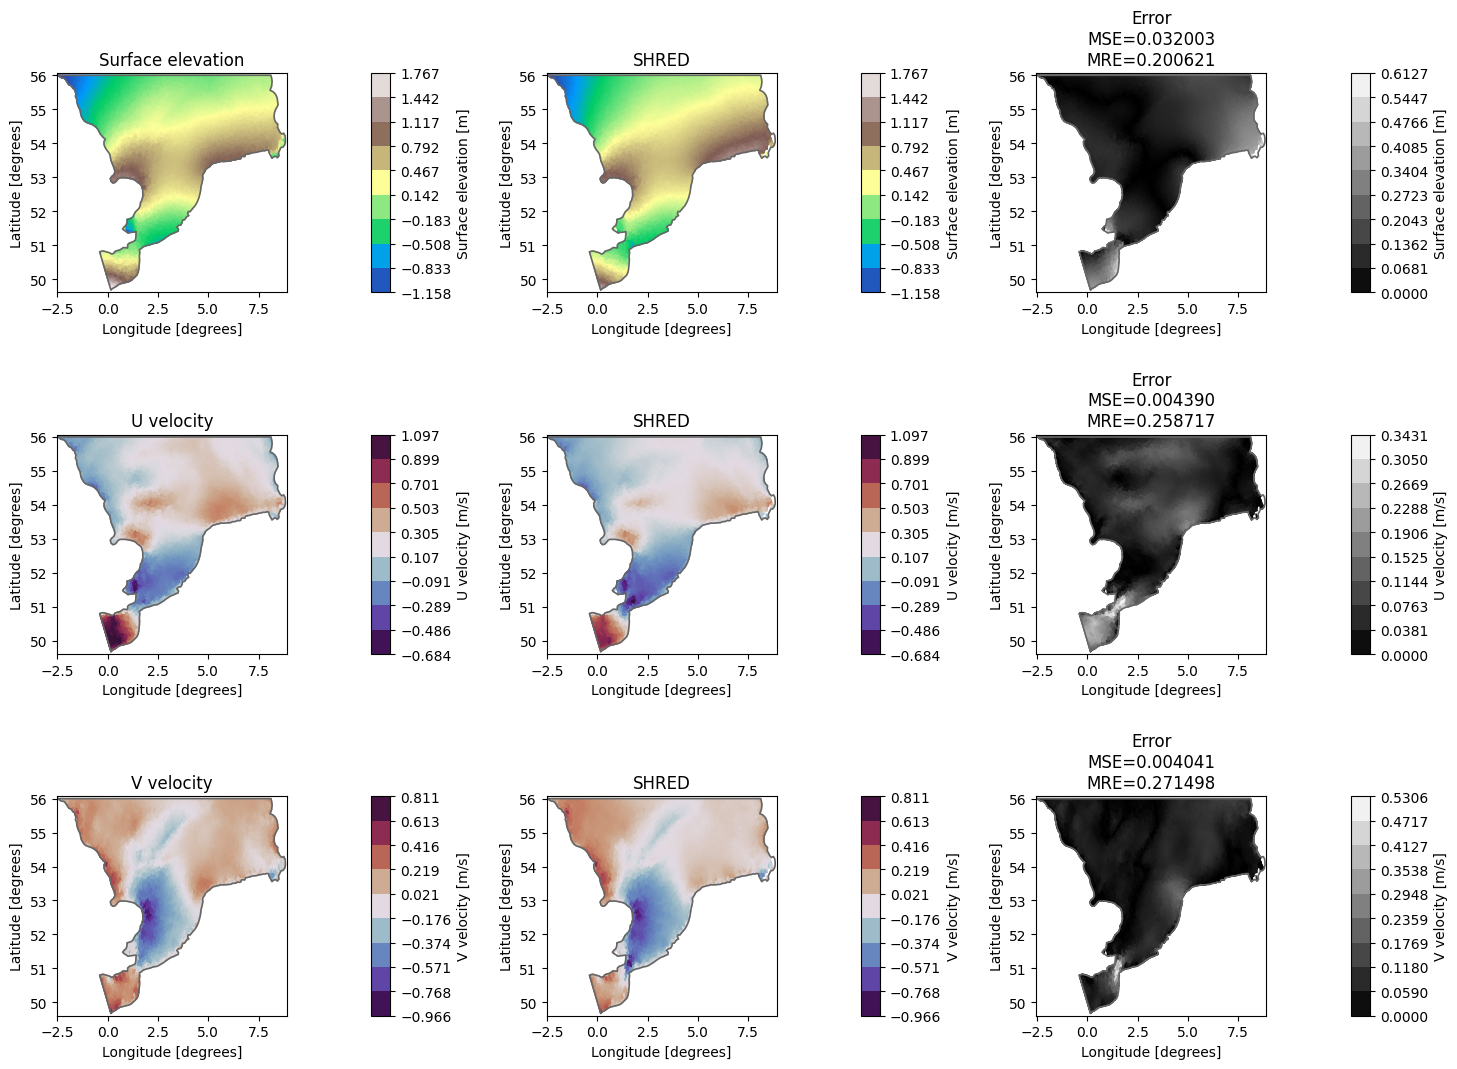

In [ ]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction(manager.test_sensor_measurements)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="T_1_C_last_value_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea S.1.C: Last value imputer

Starting training...


Training: 100%|██████████| 200/200 [09:21<00:00,  2.81s/it, Train Loss=0.0036, Val Loss=0.0041, Patience=3, Best Val Loss=0.0041, LR=0.00e+00] 

Training completed with best validation loss: 0.0041


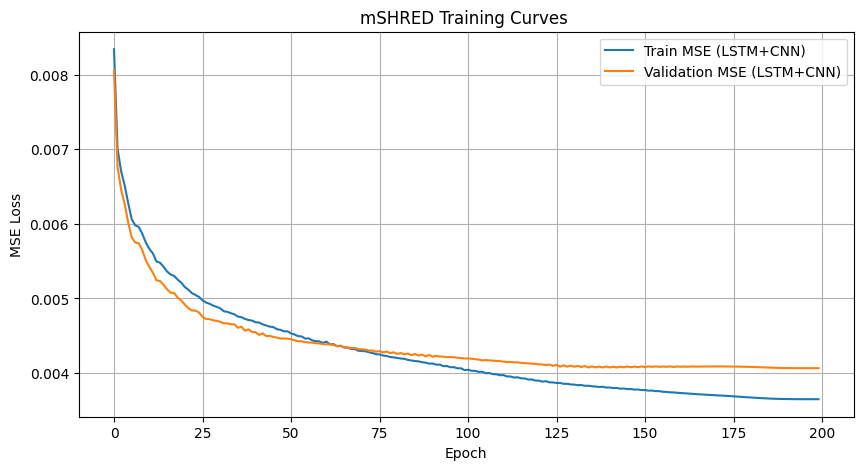

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.0) only available sensors,0.003866,0.004088,0.009840,0.124958,0.126123,0.196637
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.003766,0.004077,0.009829,0.123386,0.125691,0.195788
2,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.003823,0.004051,0.009776,0.124557,0.125758,0.195697
3,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.003676,0.004036,0.010085,0.122717,0.125418,0.197708
4,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.003764,0.003990,0.009698,0.123587,0.124648,0.194954
5,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.003631,0.003994,0.009914,0.121811,0.124570,0.196031
6,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.003748,0.004025,0.009657,0.123510,0.125180,0.194356
7,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.003648,0.004065,0.010020,0.122195,0.125475,0.197349


In [ ]:

# mSHRED TRAINING (Idea S.1.C) - LSTM + CNN
model_args_s0 = dict(
    # Encoder
    encoder="lstm",
    input_size=nn_input_shape,
    hidden_size=32,
    num_layers=2,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args_s0).to(device)

train_errors_shred, valid_errors_shred = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors_shred, label='Train MSE (LSTM+CNN)')
plt.plot(valid_errors_shred, label='Validation MSE (LSTM+CNN)')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves ')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse_shred, train_mre_shred = evaluate(mshred, train_dataset)
val_mse_shred, val_mre_shred = evaluate(mshred, val_dataset)
test_mse_shred, test_mre_shred = evaluate(mshred, test_dataset)
test_error = {
    "model": "(mSHRED) LSTM + CNN",
    "type": "(S.1.C) last value imputation for missing sensors",
    "train-mse": float(train_mse_shred),
    "val-mse": float(val_mse_shred),
    "test-mse": float(test_mse_shred),
    "train-mre": float(train_mre_shred),
    "val-mre": float(val_mre_shred),
    "test-mre": float(test_mre_shred),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_S_1_C_last_value_imputation.png


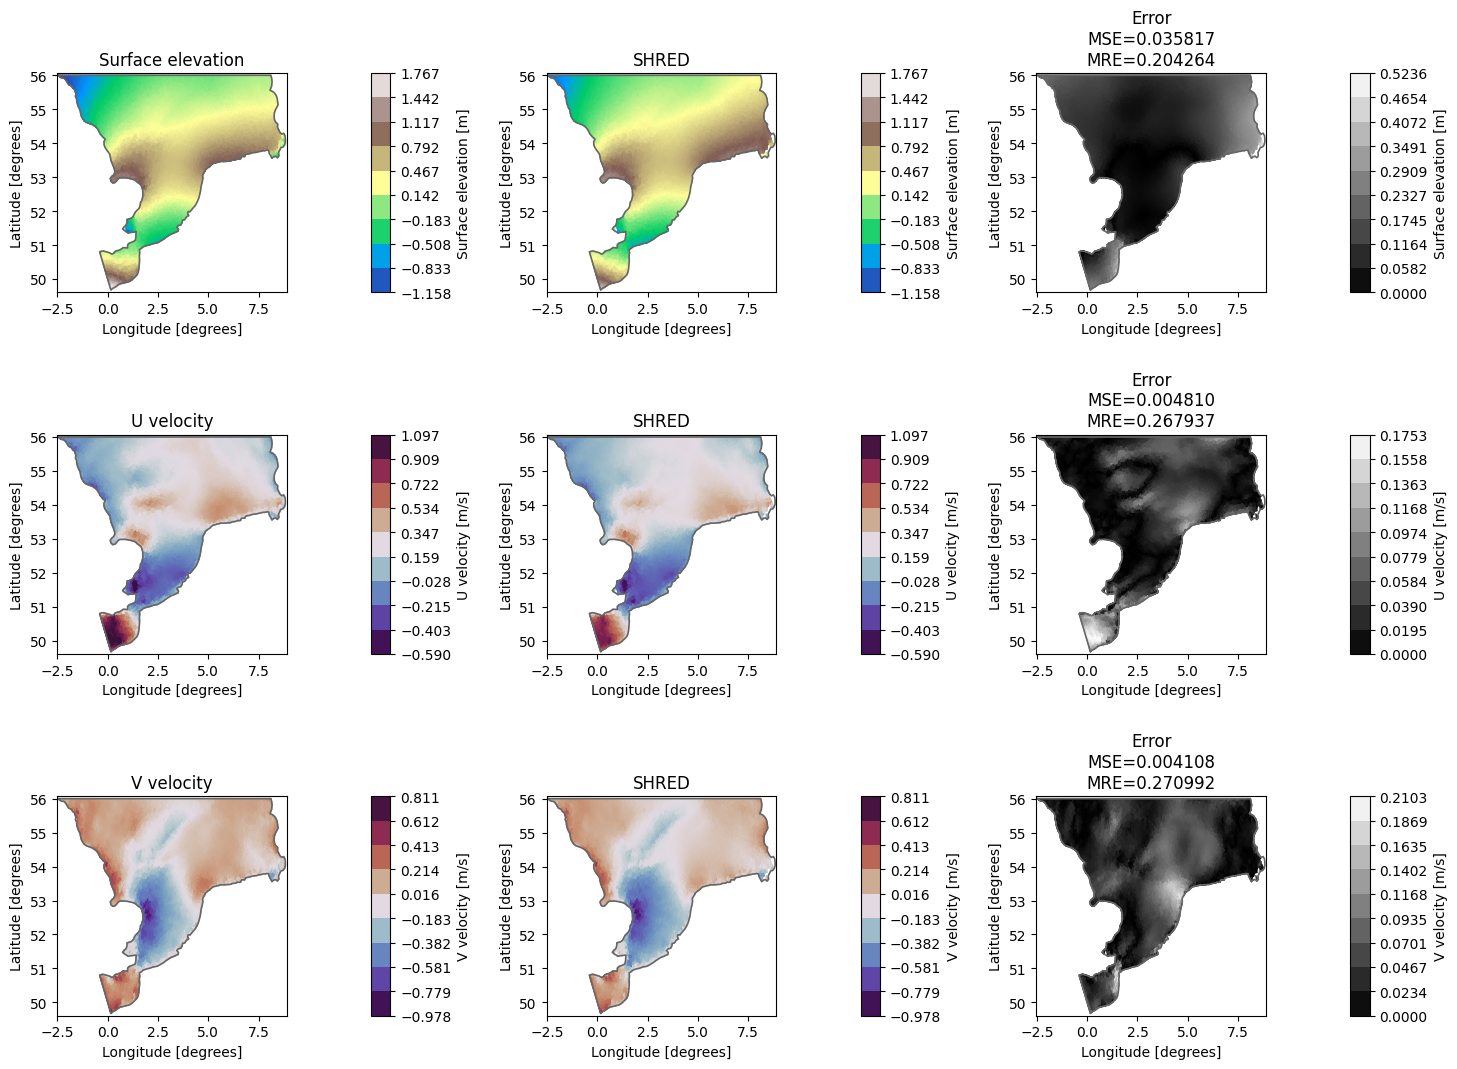

In [ ]:

# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction(manager.test_sensor_measurements)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="S_1_C_last_value_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager


## Idea 2.A: GRUD

In [ ]:

# Data manager
lags = 24
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(
    H, id = "Surface elevation" , compress = 12, 
    measurements = measurements
)
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, val_dataset, test_dataset, X_mean = manager.prepare(verbose = True, masking_type="grud")

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = measurements.shape[1]
nn_output_shape = manager.data.shape[1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Nuber of nan values in measurements after imputation: 117189 

Residual energy of Surface elevation after keeping 12 modes: 0.1678 %
Residual energy of U velocity after keeping 40 modes: 0.1947 %
Residual energy of V velocity after keeping 68 modes: 0.1872 %

 Data shapes after preparation:
Train:	 torch.Size([28031, 4, 24, 16]) -> torch.Size([28031, 120])
Val:	 torch.Size([3504, 4, 24, 16]) -> torch.Size([3504, 120])
Test:	 torch.Size([3504, 4, 24, 16]) -> torch.Size([3504, 120])

Input shape for the model: 16
Output shape for the model: 120


Starting training...


Training: 100%|██████████| 200/200 [36:52<00:00, 11.06s/it, Train Loss=0.0040, Val Loss=0.0048, Patience=4, Best Val Loss=0.0048, LR=0.00e+00] 

Training completed with best validation loss: 0.0048


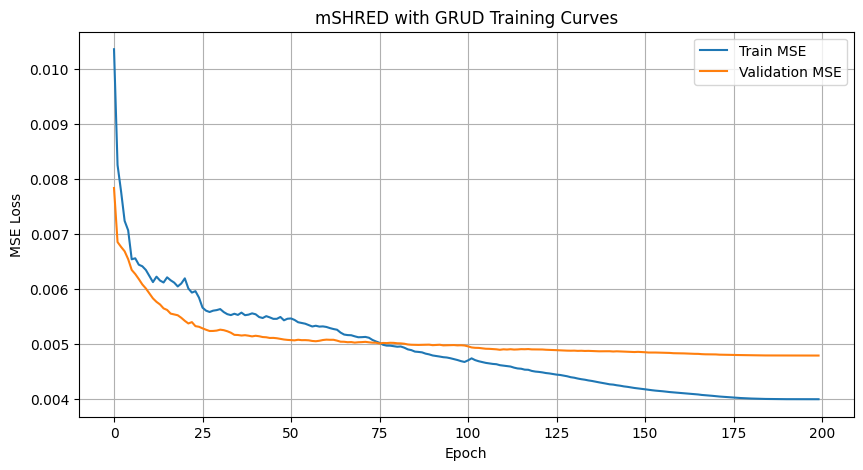

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.0) only available sensors,0.003866,0.004088,0.009840,0.124958,0.126123,0.196637
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.003766,0.004077,0.009829,0.123386,0.125691,0.195788
2,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.003823,0.004051,0.009776,0.124557,0.125758,0.195697
3,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.003676,0.004036,0.010085,0.122717,0.125418,0.197708
4,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.003764,0.003990,0.009698,0.123587,0.124648,0.194954
5,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.003631,0.003994,0.009914,0.121811,0.124570,0.196031
6,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.003748,0.004025,0.009657,0.123510,0.125180,0.194356
7,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.003648,0.004065,0.010020,0.122195,0.125475,0.197349
8,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.003988,0.004783,0.010789,0.127445,0.137910,0.205584


In [ ]:
# GRUD TRAINING
model_args = dict(
    # Encoder
    encoder="grud",
    input_size=nn_input_shape,
    hidden_size=32,
    X_mean=X_mean,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED with GRUD Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): GRUD + CNN",
    "type" : "(2.A) GRUD masking",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_2_A_GRUD_masking.png


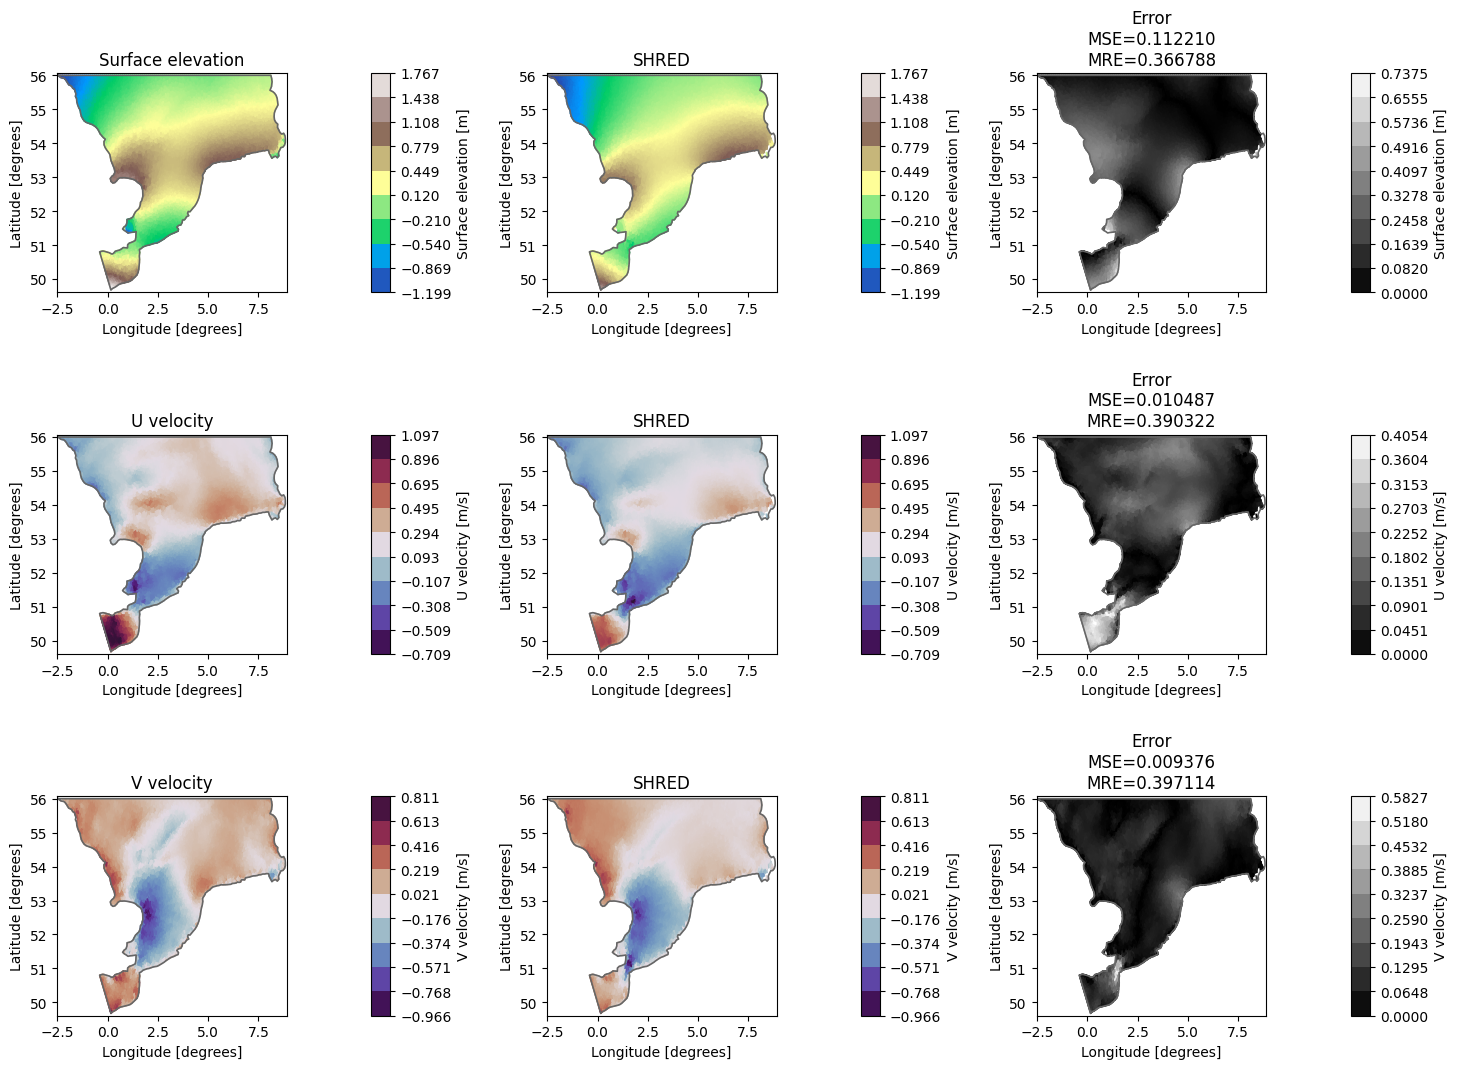

In [ ]:

# mSHRED RECONSTRUCTION

engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction(manager.test_sensor_measurements)
ds_grud, ds_error_grud = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="2_A_GRUD_masking")

del engine, test_reconstruction, ds_grud, ds_error_grud, mshred


## Idea 2.B: Attn AGRUD


Starting training...


Training: 100%|██████████| 200/200 [55:18<00:00, 16.59s/it, Train Loss=0.0041, Val Loss=0.0050, Patience=14, Best Val Loss=0.0050, LR=0.00e+00]

Training completed with best validation loss: 0.0050


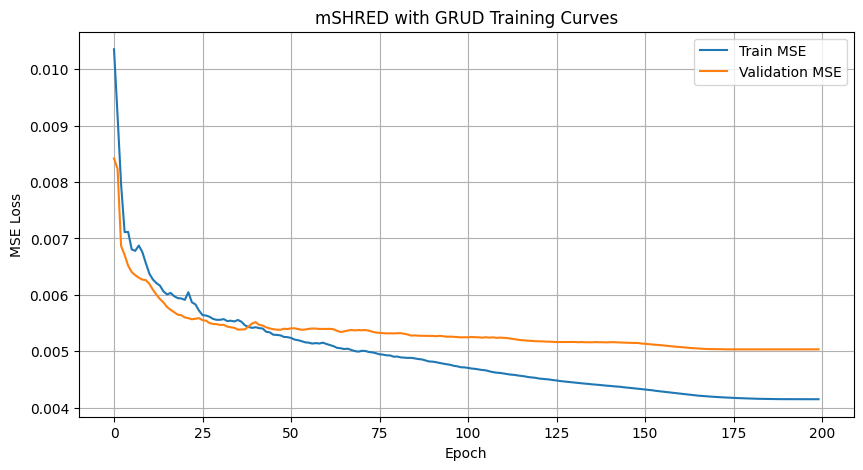

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.0) only available sensors,0.003866,0.004088,0.009840,0.124958,0.126123,0.196637
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.003766,0.004077,0.009829,0.123386,0.125691,0.195788
2,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.003823,0.004051,0.009776,0.124557,0.125758,0.195697
3,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.003676,0.004036,0.010085,0.122717,0.125418,0.197708
4,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.003764,0.003990,0.009698,0.123587,0.124648,0.194954
5,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.003631,0.003994,0.009914,0.121811,0.124570,0.196031
6,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.003748,0.004025,0.009657,0.123510,0.125180,0.194356
7,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.003648,0.004065,0.010020,0.122195,0.125475,0.197349
8,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.003988,0.004783,0.010789,0.127445,0.137910,0.205584
9,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.004149,0.005033,0.011589,0.129988,0.142234,0.212643


In [ ]:
# GRUD TRAINING
model_args = dict(
    # Encoder
    encoder="att_grud",
    input_size=nn_input_shape,
    hidden_size=32,
    X_mean=X_mean,

    # Decoder
    decoder="cnn",
    decoder_hidden_sizes=[64],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED with GRUD Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset)
val_mse, val_mre = evaluate(mshred, val_dataset)
test_mse, test_mre = evaluate(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): attnGRUD + CNN",
    "type" : "(2.B) GRUD masking",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_2_B_attnGRUD_masking.png


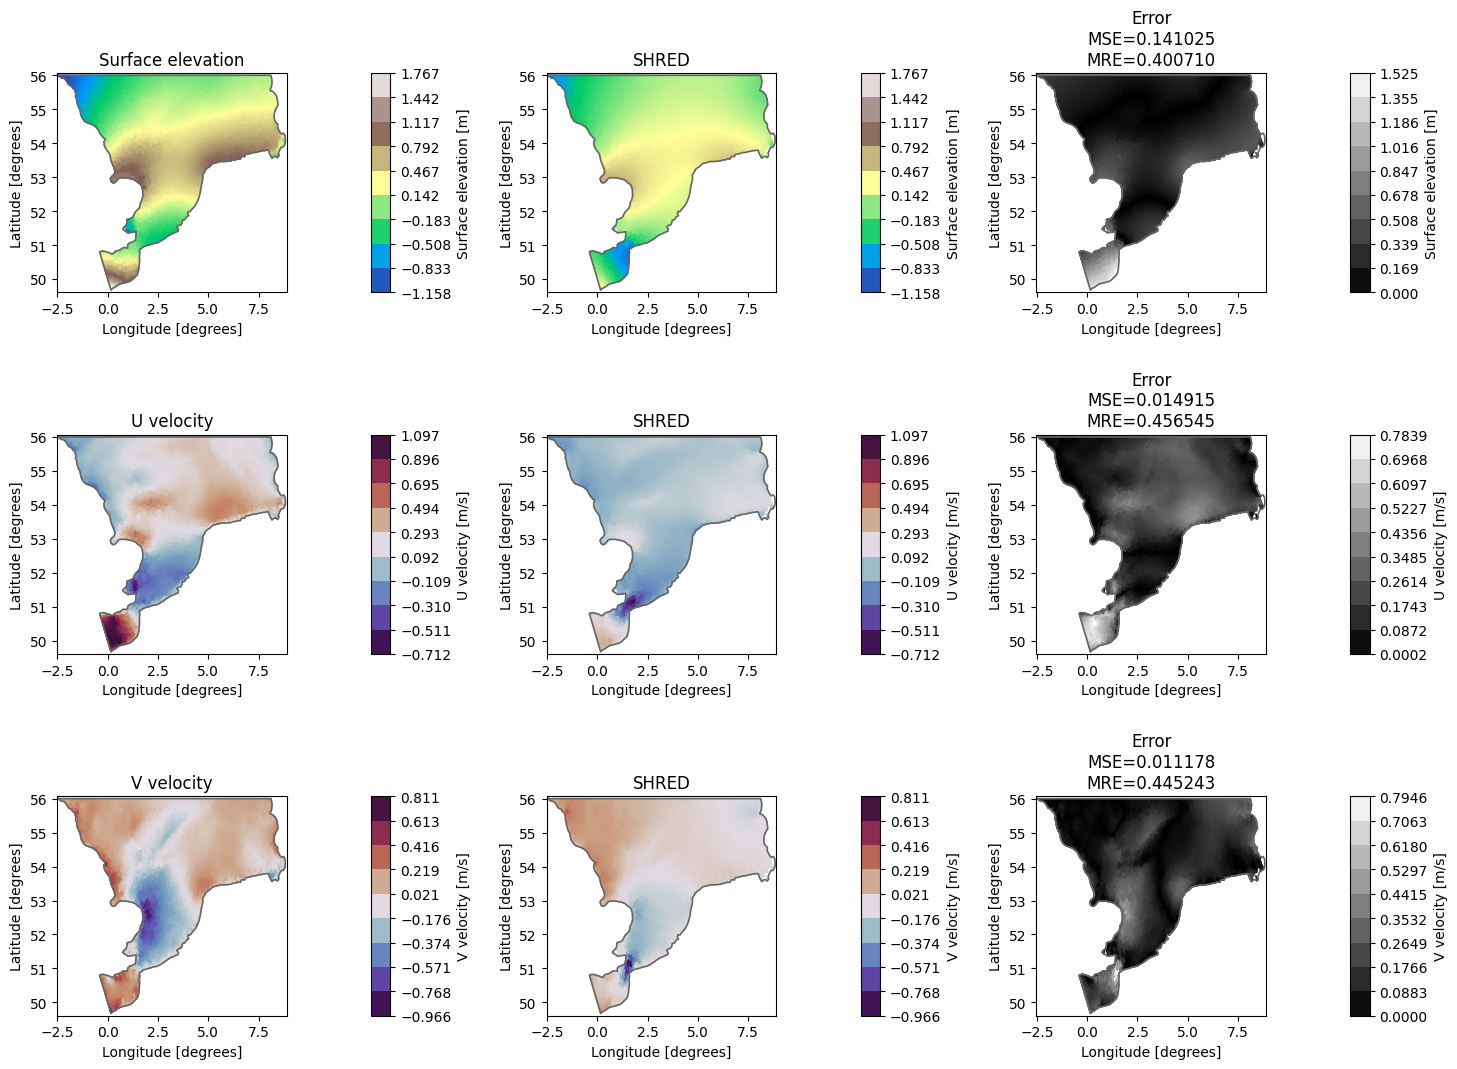

In [ ]:

# mSHRED RECONSTRUCTION

engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction(manager.test_sensor_measurements)
ds_grud, ds_error_grud = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="2_B_attnGRUD_masking")

del engine, test_reconstruction, ds_grud, ds_error_grud, mshred, manager


## Baseline Results

In [ ]:
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + CNN,(T.0) only available sensors,0.003866,0.004088,0.009840,0.124958,0.126123,0.196637
1,(mSHRED) LSTM + CNN,(S.0) only available sensors,0.003766,0.004077,0.009829,0.123386,0.125691,0.195788
2,(mSHRED): TR + CNN,(T.1.A) median imputation for missing sensors,0.003823,0.004051,0.009776,0.124557,0.125758,0.195697
3,(mSHRED) LSTM + CNN,(S.1.A) median imputation for missing sensors,0.003676,0.004036,0.010085,0.122717,0.125418,0.197708
4,(mSHRED): TR + CNN,(T.1.B) mean imputation for missing sensors,0.003764,0.003990,0.009698,0.123587,0.124648,0.194954
5,(mSHRED) LSTM + CNN,(S.1.B) mean imputation for missing sensors,0.003631,0.003994,0.009914,0.121811,0.124570,0.196031
6,(mSHRED): TR + CNN,(T.1.C) last value imputation for missing sensors,0.003748,0.004025,0.009657,0.123510,0.125180,0.194356
7,(mSHRED) LSTM + CNN,(S.1.C) last value imputation for missing sensors,0.003648,0.004065,0.010020,0.122195,0.125475,0.197349
8,(mSHRED): GRUD + CNN,(2.A) GRUD masking,0.003988,0.004783,0.010789,0.127445,0.137910,0.205584
9,(mSHRED): attnGRUD + CNN,(2.B) GRUD masking,0.004149,0.005033,0.011589,0.129988,0.142234,0.212643


## Run 1: lag 48

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>model</th>
      <th>type</th>
      <th>train-mse</th>
      <th>val-mse</th>
      <th>test-mse</th>
      <th>train-mre</th>
      <th>val-mre</th>
      <th>test-mre</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>(mSHRED): TR + CNN</td>
      <td>(T.0) only available sensors</td>
      <td>0.003985</td>
      <td>0.004123</td>
      <td>0.009929</td>
      <td>0.126815</td>
      <td>0.127359</td>
      <td>0.197460</td>
    </tr>
    <tr>
      <th>1</th>
      <td>(mSHRED) LSTM + CNN</td>
      <td>(S.0) only available sensors</td>
      <td>0.003695</td>
      <td>0.004035</td>
      <td>0.009714</td>
      <td>0.122322</td>
      <td>0.125067</td>
      <td>0.194747</td>
    </tr>
    <tr>
      <th>2</th>
      <td>(mSHRED): TR + CNN</td>
      <td>(T.1.A) median imputation for missing sensors</td>
      <td>0.003908</td>
      <td>0.004072</td>
      <td>0.009839</td>
      <td>0.126051</td>
      <td>0.126587</td>
      <td>0.195943</td>
    </tr>
    <tr>
      <th>3</th>
      <td>(mSHRED) LSTM + CNN</td>
      <td>(S.1.A) median imputation for missing sensors</td>
      <td>0.003531</td>
      <td>0.003936</td>
      <td>0.009655</td>
      <td>0.120112</td>
      <td>0.123786</td>
      <td>0.193737</td>
    </tr>
    <tr>
      <th>4</th>
      <td>(mSHRED): TR + CNN</td>
      <td>(T.1.B) mean imputation for missing sensors</td>
      <td>0.003883</td>
      <td>0.004070</td>
      <td>0.009869</td>
      <td>0.125496</td>
      <td>0.126119</td>
      <td>0.196341</td>
    </tr>
    <tr>
      <th>5</th>
      <td>(mSHRED) LSTM + CNN</td>
      <td>(S.1.B) mean imputation for missing sensors</td>
      <td>0.003535</td>
      <td>0.003940</td>
      <td>0.009654</td>
      <td>0.120142</td>
      <td>0.123643</td>
      <td>0.194001</td>
    </tr>
    <tr>
      <th>6</th>
      <td>(mSHRED): TR + CNN</td>
      <td>(T.1.C) last value imputation for missing sensors</td>
      <td>0.003842</td>
      <td>0.004047</td>
      <td>0.009830</td>
      <td>0.125010</td>
      <td>0.125792</td>
      <td>0.195648</td>
    </tr>
    <tr>
      <th>7</th>
      <td>(mSHRED) LSTM + CNN</td>
      <td>(S.1.C) last value imputation for missing sensors</td>
      <td>0.003540</td>
      <td>0.004031</td>
      <td>0.009846</td>
      <td>0.120422</td>
      <td>0.125105</td>
      <td>0.195499</td>
    </tr>
    <tr>
      <th>8</th>
      <td>(mSHRED): GRUD + CNN</td>
      <td>(T.2) GRUD masking</td>
      <td>0.004492</td>
      <td>0.004974</td>
      <td>0.010931</td>
      <td>0.136508</td>
      <td>0.141720</td>
      <td>0.206276</td>
    </tr>
  </tbody>
</table>
</div>

## Run 2: lag 96

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>model</th>
      <th>type</th>
      <th>train-mse</th>
      <th>val-mse</th>
      <th>test-mse</th>
      <th>train-mre</th>
      <th>val-mre</th>
      <th>test-mre</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>(mSHRED): TR + CNN</td>
      <td>(T.0) only available sensors</td>
      <td>0.004024</td>
      <td>0.004339</td>
      <td>0.010870</td>
      <td>0.128745</td>
      <td>0.131210</td>
      <td>0.206686</td>
    </tr>
    <tr>
      <th>1</th>
      <td>(mSHRED) LSTM + CNN</td>
      <td>(S.0) only available sensors</td>
      <td>0.003865</td>
      <td>0.004255</td>
      <td>0.010616</td>
      <td>0.126571</td>
      <td>0.130015</td>
      <td>0.204549</td>
    </tr>
    <tr>
      <th>2</th>
      <td>(mSHRED): TR + CNN</td>
      <td>(T.1.A) median imputation for missing sensors</td>
      <td>0.004068</td>
      <td>0.004343</td>
      <td>0.010872</td>
      <td>0.129262</td>
      <td>0.131078</td>
      <td>0.206476</td>
    </tr>
    <tr>
      <th>3</th>
      <td>(mSHRED) LSTM + CNN</td>
      <td>(S.1.A) median imputation for missing sensors</td>
      <td>0.003732</td>
      <td>0.004235</td>
      <td>0.010673</td>
      <td>0.124545</td>
      <td>0.129395</td>
      <td>0.204780</td>
    </tr>
    <tr>
      <th>4</th>
      <td>(mSHRED): TR + CNN</td>
      <td>(T.1.B) mean imputation for missing sensors</td>
      <td>0.003919</td>
      <td>0.004272</td>
      <td>0.010707</td>
      <td>0.127227</td>
      <td>0.130153</td>
      <td>0.205130</td>
    </tr>
    <tr>
      <th>5</th>
      <td>(mSHRED) LSTM + CNN</td>
      <td>(S.1.B) mean imputation for missing sensors</td>
      <td>0.003756</td>
      <td>0.004242</td>
      <td>0.010719</td>
      <td>0.124983</td>
      <td>0.129404</td>
      <td>0.205380</td>
    </tr>
    <tr>
      <th>6</th>
      <td>(mSHRED): TR + CNN</td>
      <td>(T.1.C) last value imputation for missing sensors</td>
      <td>0.003939</td>
      <td>0.004311</td>
      <td>0.010769</td>
      <td>0.127407</td>
      <td>0.130737</td>
      <td>0.205711</td>
    </tr>
    <tr>
      <th>7</th>
      <td>(mSHRED) LSTM + CNN</td>
      <td>(S.1.C) last value imputation for missing sensors</td>
      <td>0.003606</td>
      <td>0.004264</td>
      <td>0.011033</td>
      <td>0.122902</td>
      <td>0.129759</td>
      <td>0.207379</td>
    </tr>
    <tr>
      <th>8</th>
      <td>(mSHRED): GRUD + CNN</td>
      <td>(T.2) GRUD masking</td>
      <td>0.004052</td>
      <td>0.004852</td>
      <td>0.011647</td>
      <td>0.129994</td>
      <td>0.140247</td>
      <td>0.214029</td>
    </tr>
  </tbody>
</table>
</div>

## Run 3: lag 24

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>model</th>
      <th>type</th>
      <th>train-mse</th>
      <th>val-mse</th>
      <th>test-mse</th>
      <th>train-mre</th>
      <th>val-mre</th>
      <th>test-mre</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>(mSHRED): TR + CNN</td>
      <td>(T.0) only available sensors</td>
      <td>0.003866</td>
      <td>0.004088</td>
      <td>0.009840</td>
      <td>0.124958</td>
      <td>0.126123</td>
      <td>0.196637</td>
    </tr>
    <tr>
      <th>1</th>
      <td>(mSHRED) LSTM + CNN</td>
      <td>(S.0) only available sensors</td>
      <td>0.003766</td>
      <td>0.004077</td>
      <td>0.009829</td>
      <td>0.123386</td>
      <td>0.125691</td>
      <td>0.195788</td>
    </tr>
    <tr>
      <th>2</th>
      <td>(mSHRED): TR + CNN</td>
      <td>(T.1.A) median imputation for missing sensors</td>
      <td>0.003823</td>
      <td>0.004051</td>
      <td>0.009776</td>
      <td>0.124557</td>
      <td>0.125758</td>
      <td>0.195697</td>
    </tr>
    <tr>
      <th>3</th>
      <td>(mSHRED) LSTM + CNN</td>
      <td>(S.1.A) median imputation for missing sensors</td>
      <td>0.003676</td>
      <td>0.004036</td>
      <td>0.010085</td>
      <td>0.122717</td>
      <td>0.125418</td>
      <td>0.197708</td>
    </tr>
    <tr>
      <th>4</th>
      <td>(mSHRED): TR + CNN</td>
      <td>(T.1.B) mean imputation for missing sensors</td>
      <td>0.003764</td>
      <td>0.003990</td>
      <td>0.009698</td>
      <td>0.123587</td>
      <td>0.124648</td>
      <td>0.194954</td>
    </tr>
    <tr>
      <th>5</th>
      <td>(mSHRED) LSTM + CNN</td>
      <td>(S.1.B) mean imputation for missing sensors</td>
      <td>0.003631</td>
      <td>0.003994</td>
      <td>0.009914</td>
      <td>0.121811</td>
      <td>0.124570</td>
      <td>0.196031</td>
    </tr>
    <tr>
      <th>6</th>
      <td>(mSHRED): TR + CNN</td>
      <td>(T.1.C) last value imputation for missing sensors</td>
      <td>0.003748</td>
      <td>0.004025</td>
      <td>0.009657</td>
      <td>0.123510</td>
      <td>0.125180</td>
      <td>0.194356</td>
    </tr>
    <tr>
      <th>7</th>
      <td>(mSHRED) LSTM + CNN</td>
      <td>(S.1.C) last value imputation for missing sensors</td>
      <td>0.003648</td>
      <td>0.004065</td>
      <td>0.010020</td>
      <td>0.122195</td>
      <td>0.125475</td>
      <td>0.197349</td>
    </tr>
    <tr>
      <th>8</th>
      <td>(mSHRED): GRUD + CNN</td>
      <td>(2.A) GRUD masking</td>
      <td>0.003988</td>
      <td>0.004783</td>
      <td>0.010789</td>
      <td>0.127445</td>
      <td>0.137910</td>
      <td>0.205584</td>
    </tr>
    <tr>
      <th>9</th>
      <td>(mSHRED): attnGRUD + CNN</td>
      <td>(2.B) GRUD masking</td>
      <td>0.004149</td>
      <td>0.005033</td>
      <td>0.011589</td>
      <td>0.129988</td>
      <td>0.142234</td>
      <td>0.212643</td>
    </tr>
  </tbody>
</table>
</div>

## 